<a href="https://colab.research.google.com/github/bahaali273/COMP9170-Hospital-Readmission/blob/bahaa-dev/notebooks/02_mlp_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hospital Readmission Prediction: MLP Neural Network

**COMP 9170 — Data Science Group Project**

**Author:** Bahaa Al-Juboori  
**Model:** Multi-Layer Perceptron (MLP)  
**Dataset:** UCI Diabetes 130-US Hospitals (1999–2008)

## 1. Data Loading and Validation

### Decisions
- Use the cleaned training and testing datasets generated by the shared preprocessing pipeline.
- Verify dataset dimensions, target availability, and missing values.
- Preserve the original test dataset for final evaluation.

### Results
- Training dataset: 55,976 rows × 134 columns.
- Testing dataset: 13,994 rows × 134 columns.
- 133 input features and one binary target (`readmit_30`).
- No missing values in either dataset.

In [1]:

import pandas as pd
import numpy as np

# Load the processed datasets created by Jason's pipeline
train_df = pd.read_csv("/content/train_clean.csv")
test_df = pd.read_csv("/content/test_clean.csv")

# Inspect dataset dimensions
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

# Check the target column
print("Target exists:", "readmit_30" in train_df.columns)

# Check missing values
print("Training missing values:", train_df.isna().sum().sum())
print("Testing missing values:", test_df.isna().sum().sum())



Training shape: (55976, 134)
Testing shape: (13994, 134)
Target exists: True
Training missing values: 0
Testing missing values: 0


## 2. Training and Validation Split

### Decisions
- Split the original training set into 80% training and 20% validation.
- Use stratified sampling to maintain the positive-class prevalence.
- Fix `random_state=42` for reproducibility.
- Keep the original test set untouched during model development.

### Results
- Training: 44,780 samples × 133 features.
- Validation: 11,196 samples × 133 features.
- Testing: 13,994 samples × 133 features.
- Positive-class prevalence: approximately 8.97% in all three sets.

In [2]:

from sklearn.model_selection import train_test_split

TARGET = "readmit_30"
SEED = 42

# Separate input features and target labels
X = train_df.drop(columns=[TARGET])
y = train_df[TARGET]

# Create training and validation subsets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Keep the original test dataset untouched
X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Training prevalence:", round(y_train.mean(), 4))
print("Validation prevalence:", round(y_val.mean(), 4))
print("Testing prevalence:", round(y_test.mean(), 4))


X_train: (44780, 133)
X_val: (11196, 133)
X_test: (13994, 133)
Training prevalence: 0.0897
Validation prevalence: 0.0897
Testing prevalence: 0.0897



## 3. Feature Scaling

### Decisions
- Apply StandardScaler to numeric input features.
- Fit the scaler using the training set only to avoid data leakage.
- Apply the learned scaling parameters to validation and test sets.
- Preserve the same feature order across all datasets.
- Verify that transformed arrays contain only finite values.

### Results
- Training: 44,780 samples × 133 features.
- Validation: 11,196 samples × 133 features.
- Testing: 13,994 samples × 133 features.
- The first five scaled training features have means approximately equal to 0.
- The first five scaled training features have standard deviations equal to 1.
- All transformed values are finite across training, validation, and testing datasets.
- The scaler was fitted exclusively on training data.


In [3]:

from sklearn.preprocessing import StandardScaler
import numpy as np

# Initialize the feature scaler
scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to unseen data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Verify dimensions and numerical validity
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("Train mean (first 5 features):",
      np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("Train std (first 5 features):",
      np.round(X_train_scaled.std(axis=0)[:5], 4))

print("All values finite:",
      np.isfinite(X_train_scaled).all()
      and np.isfinite(X_val_scaled).all()
      and np.isfinite(X_test_scaled).all())


Train: (44780, 133)
Validation: (11196, 133)
Test: (13994, 133)
Train mean (first 5 features): [-0.  0.  0. -0. -0.]
Train std (first 5 features): [1. 1. 1. 1. 1.]
All values finite: True



## 4. MLP Architecture

### Decisions
- Use a feed-forward Multi-Layer Perceptron for binary classification.
- Input dimension: 133 numerical features.
- Use two hidden layers with 64 and 32 neurons.
- Apply ReLU activation to hidden layers.
- Use a Sigmoid output to estimate the probability of 30-day readmission.
- Set random seeds to improve reproducibility.
- Start with a simple architecture before experimenting with more complex networks.


### Results
- Successfully initialized a feed-forward MLP neural network.
- Input features: 133.
- First hidden layer: 64 neurons with ReLU activation.
- Second hidden layer: 32 neurons with ReLU activation.
- Output layer: 1 neuron with Sigmoid activation.
- Total trainable parameters: 10,689.
- Non-trainable parameters: 0.
- The model architecture is ready for compilation and training.



In [4]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Define the MLP model
model = keras.Sequential([
    layers.Input(shape=(133,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         8,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,689 (41.75 KB)

 Trainable params: 10,689 (41.75 KB)

 Non-trainable params: 0 (0.00 B)


## 5. Model Compilation

### Decisions
- Use Adam optimizer with a learning rate of 0.001.
- Use binary cross-entropy as the loss function for binary classification.
- Monitor Precision-Recall AUC (PR-AUC) because the positive class represents only 8.97% of observations.
- Track ROC-AUC as a secondary evaluation metric.
- Use validation data during training while keeping the test set untouched.

### Results
- Model compilation completed successfully.
- Optimizer: Adam with learning rate = 0.001.
- Loss function: Binary Cross-Entropy.
- Evaluation metrics: PR-AUC and ROC-AUC.
- The MLP is ready for training.


In [5]:

from tensorflow.keras import optimizers, metrics

model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        metrics.AUC(name="pr_auc", curve="PR"),
        metrics.AUC(name="roc_auc", curve="ROC")
    ]
)

print("Model compiled successfully!")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss: Binary Cross-Entropy")
print("Metrics: PR-AUC, ROC-AUC")


Model compiled successfully!
Optimizer: Adam
Learning rate: 0.001
Loss: Binary Cross-Entropy
Metrics: PR-AUC, ROC-AUC



## 6. Model Training

### Decisions
- Train the MLP using the training set only.
- Use balanced class weights to address the minority readmission class.
- Use a maximum of 50 epochs and batch size of 256.
- Monitor validation PR-AUC to assess performance on the minority class.
- Apply Early Stopping with patience = 7.
- Restore the best model weights based on validation PR-AUC.
- Keep the test set untouched throughout training.


### Results
- Class weights: Negative = 0.5493, Positive = 5.5724.
- Maximum epochs: 50; actual training stopped after 9 epochs.
- Best validation PR-AUC: 0.1523 (Epoch 2).
- Training PR-AUC increased from 0.1259 to 0.2699.
- Validation PR-AUC declined after Epoch 2, indicating overfitting.
- Early Stopping restored the best model weights.
- The model outperformed the approximate random PR-AUC baseline of 0.0897.
- Further experiments with regularization and model complexity are needed.
- The held-out test set has not been used.



In [6]:

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# Compute class weights from training labels only
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes.tolist(), weights.tolist()))

print("Class weights:", class_weights)

# Stop training when validation PR-AUC stops improving
early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=7,
    restore_best_weights=True
)

# Train the MLP
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("Training completed!")
print("Epochs trained:", len(history.history["loss"]))
print("Best validation PR-AUC:",
      round(max(history.history["val_pr_auc"]), 4))


Class weights: {0: 0.5492860997988323, 1: 5.5724240915878545}
Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.6876 - pr_auc: 0.1259 - roc_auc: 0.5871 - val_loss: 0.6907 - val_pr_auc: 0.1506 - val_roc_auc: 0.6287
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6543 - pr_auc: 0.1641 - roc_auc: 0.6547 - val_loss: 0.6770 - val_pr_auc: 0.1523 - val_roc_auc: 0.6358
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6402 - pr_auc: 0.1827 - roc_auc: 0.6804 - val_loss: 0.6720 - val_pr_auc: 0.1521 - val_roc_auc: 0.6365
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6286 - pr_auc: 0.1979 - roc_auc: 0.6994 - val_loss: 0.6674 - val_pr_auc: 0.1510 - val_roc_auc: 0.6354
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6176 - pr_auc: 0.2121 - roc_auc: 0.7161 - val_loss: 0.6635 - val_pr_auc: 0.1495 - val_roc_auc: 0.6340
Epoch 6/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6064 - pr_auc: 0.2267 - roc_auc: 0.7316 - val_loss: 0.6


## 7. Training Performance Visualization

### Decisions
- Plot training and validation PR-AUC across epochs.
- Plot training and validation loss.
- Identify the epoch with the highest validation PR-AUC.
- Use the plots to investigate overfitting without accessing test data.

### Results
- Both PR-AUC and loss curves were generated successfully.
- Best validation PR-AUC: 0.1523 at Epoch 2.
- Training PR-AUC increased throughout the 9 epochs.
- Validation PR-AUC decreased after Epoch 2.
- Training loss continued decreasing, while validation loss began to plateau.
- The curves indicate overfitting.
- Early Stopping restored the model weights from Epoch 2.
- Further regularization experiments are warranted.


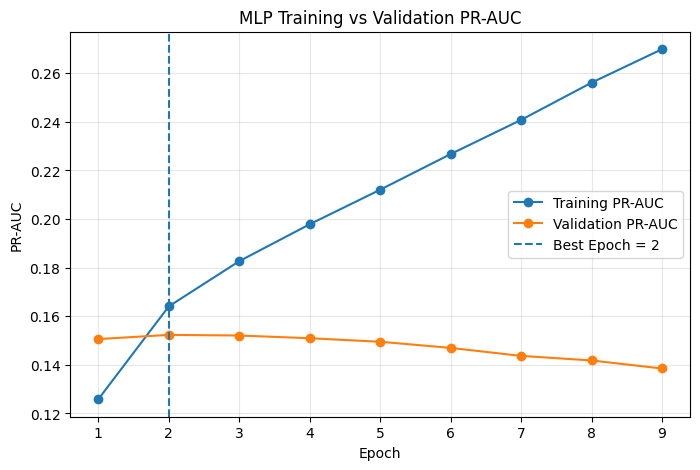

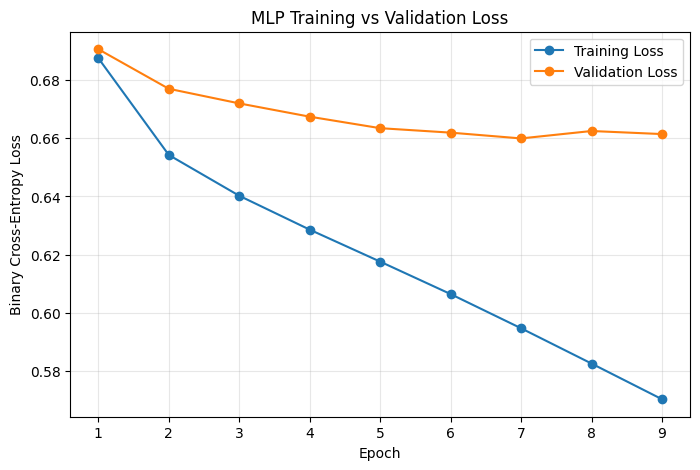

Best epoch: 2
Best validation PR-AUC: 0.1523


In [7]:

import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(history.history["loss"]) + 1)

best_epoch = np.argmax(history.history["val_pr_auc"]) + 1

# PR-AUC plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["pr_auc"],
         marker="o", label="Training PR-AUC")
plt.plot(epochs, history.history["val_pr_auc"],
         marker="o", label="Validation PR-AUC")
plt.axvline(best_epoch, linestyle="--",
            label=f"Best Epoch = {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.title("MLP Training vs Validation PR-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["loss"],
         marker="o", label="Training Loss")
plt.plot(epochs, history.history["val_loss"],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("MLP Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best epoch:", best_epoch)
print("Best validation PR-AUC:",
      round(max(history.history["val_pr_auc"]), 4))



## 8. Regularized MLP Architecture

### Decisions
- Preserve the original MLP as the baseline model.
- Create a separate model using L2 regularization and Dropout.
- Retain the same 133 input features and 64/32 hidden-layer architecture.
- Apply L2 regularization with strength 0.001.
- Apply Dropout with rate 0.3 after each hidden layer.
- Use the same training and validation sets for a fair comparison.
- Compare validation PR-AUC before selecting the final model.
- Keep the held-out test set untouched.


### Results
- Successfully initialized a regularized MLP model.
- Input dimension: 133 features.
- Hidden layers: 64 and 32 neurons with ReLU activation.
- Dropout rate: 0.30 after each hidden layer.
- L2 regularization strength: 0.001.
- Output layer: one Sigmoid neuron.
- Total trainable parameters: 10,689.
- Non-trainable parameters: 0.
- The original baseline MLP remains unchanged.
- The regularized model is ready for compilation and training.



In [8]:

from tensorflow import keras
from tensorflow.keras import layers, regularizers

# Ensure reproducibility
keras.utils.set_random_seed(42)

# Create a new model without changing the original
regularized_model = keras.Sequential([
    layers.Input(shape=(133,)),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),

    layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

regularized_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         8,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,689 (41.75 KB)

 Trainable params: 10,689 (41.75 KB)

 Non-trainable params: 0 (0.00 B)


## 9. Regularized MLP Training

### Decisions
- Compile the regularized MLP using Adam with learning rate 0.001.
- Use binary cross-entropy as the loss function.
- Monitor PR-AUC and ROC-AUC.
- Use the same training and validation sets as the baseline MLP.
- Reuse the same class weights to address class imbalance.
- Train for a maximum of 50 epochs with batch size 256.
- Apply Early Stopping with patience 7, monitoring validation PR-AUC.
- Restore the weights corresponding to the best validation PR-AUC.
- Keep the held-out test set untouched.


### Results
- Regularized MLP training completed successfully.
- Class weights: Negative = 0.5493, Positive = 5.5724.
- Maximum training epochs: 50.
- Actual epochs trained: 21.
- Best validation PR-AUC: 0.1569 at Epoch 14.
- Baseline MLP best validation PR-AUC: 0.1523.
- Absolute PR-AUC improvement: 0.0046.
- Relative improvement: approximately 3.0%.
- Early Stopping restored the best model weights.
- Dropout and L2 regularization produced a modest validation improvement in this experiment.
- The held-out test set has not been evaluated.



In [9]:

from tensorflow.keras import optimizers, metrics
from tensorflow.keras.callbacks import EarlyStopping

# Compile regularized model
regularized_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        metrics.AUC(name="pr_auc", curve="PR"),
        metrics.AUC(name="roc_auc", curve="ROC")
    ]
)

# New callback to monitor the regularized model
regularized_early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=7,
    restore_best_weights=True
)

# Train using the same data and class weights
regularized_history = regularized_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[regularized_early_stopping],
    verbose=1
)

print("Training completed!")
print("Epochs trained:",
      len(regularized_history.history["loss"]))
print("Best validation PR-AUC:",
      round(max(regularized_history.history["val_pr_auc"]), 4))
print("Best epoch:",
      int(np.argmax(regularized_history.history["val_pr_auc"]) + 1))


Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.8244 - pr_auc: 0.1067 - roc_auc: 0.5492 - val_loss: 0.7822 - val_pr_auc: 0.1371 - val_roc_auc: 0.6146
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.7692 - pr_auc: 0.1382 - roc_auc: 0.6117 - val_loss: 0.7590 - val_pr_auc: 0.1482 - val_roc_auc: 0.6332
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.7448 - pr_auc: 0.1478 - roc_auc: 0.6296 - val_loss: 0.7383 - val_pr_auc: 0.1516 - val_roc_auc: 0.6425
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7287 - pr_auc: 0.1535 - roc_auc: 0.6443 - val_loss: 0.7127 - val_pr_auc: 0.1527 - val_roc_auc: 0.6460
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7115 - pr_auc: 0.1642 - roc_auc: 0.6585 - val_loss: 0.7085 - val_pr_auc: 0.1536 - val_roc_auc: 0.6472
Epoch 6/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7019 - pr_auc: 0.1658 - roc_auc: 0.6609 - val_loss: 0.6896 - val_pr_auc: 0.1554 - val_roc_auc: 0.6486
Epoch 7/50
175/


## 10. Validation Model Comparison

### Decisions
- Compare baseline and regularized MLP models on the same validation set.
- Compute PR-AUC and ROC-AUC from predicted probabilities.
- Compute Precision, Recall, and F1-score using an initial threshold of 0.5.
- Use validation results for model selection.
- Keep the held-out test set untouched.


### Results
- Both models were evaluated on the same validation set.
- Baseline MLP: PR-AUC = 0.1532, ROC-AUC = 0.6357, Precision = 0.1294, Recall = 0.6145, F1 = 0.2138.
- Regularized MLP: PR-AUC = 0.1578, ROC-AUC = 0.6534, Precision = 0.1331, Recall = 0.6036, F1 = 0.2181.
- Regularized MLP achieved higher PR-AUC, ROC-AUC, Precision, and F1 at the default threshold of 0.5.
- Baseline MLP achieved slightly higher Recall at threshold 0.5.
- Regularized MLP was selected provisionally based on validation PR-AUC.
- The improvement is modest and has not been independently tested for statistical significance.
- The held-out test set remains untouched.


In [10]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# Generate validation probabilities
baseline_probs = model.predict(
    X_val_scaled, verbose=0
).ravel()

regularized_probs = regularized_model.predict(
    X_val_scaled, verbose=0
).ravel()

def evaluate_validation(name, probabilities, threshold=0.5):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Model": name,
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    }

comparison = pd.DataFrame([
    evaluate_validation("Baseline MLP", baseline_probs),
    evaluate_validation("Regularized MLP", regularized_probs)
])

print(comparison.round(4).to_string(index=False))


          Model  PR-AUC  ROC-AUC  Precision  Recall     F1
   Baseline MLP  0.1532   0.6357     0.1294  0.6145 0.2138
Regularized MLP  0.1578   0.6534     0.1331  0.6036 0.2181



## 11. Decision Threshold Analysis

### Decisions
- Use the selected regularized MLP model.
- Evaluate candidate classification thresholds on validation predictions only.
- Optimize F1-score as an exploratory operating-point criterion.
- Record Precision and Recall at the chosen threshold.
- Keep the held-out test set untouched.
- Treat the chosen threshold as a research operating point, not a clinical decision rule.


### Results
- Evaluated classification thresholds from 0.05 to 0.95 on the validation set.
- Selected threshold: 0.56, maximizing validation F1-score among tested thresholds.
- Precision at threshold 0.56: 0.1598.
- Recall at threshold 0.56: 0.4173.
- F1-score at threshold 0.56: 0.2311.
- At threshold 0.50, F1-score was 0.2181.
- Absolute F1 improvement: 0.0130.
- Increasing the threshold improved precision but reduced recall.
- The selected threshold is an experimental operating point, not a clinical decision rule.
- The held-out test set remains untouched.



In [11]:

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Use validation predictions from regularized MLP
thresholds = np.arange(0.05, 0.96, 0.01)

results = []

for threshold in thresholds:
    predictions = (regularized_probs >= threshold).astype(int)

    results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
best_threshold = float(best_row["Threshold"])

print("Best threshold:", best_threshold)
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1:", round(best_row["F1"], 4))


Best threshold: 0.56
Precision: 0.1598
Recall: 0.4173
F1: 0.2311



## 12. Final Held-Out Test Evaluation

### Decisions
- Evaluate the selected regularized MLP on the untouched test dataset.
- Use the fixed validation-selected threshold of 0.56.
- Report PR-AUC, ROC-AUC, Precision, Recall, and F1-score.
- Generate a confusion matrix to examine false positives and false negatives.
- Do not modify model weights, hyperparameters, or threshold based on test results.
- Interpret results as research findings, not clinical validation.


### Results
- Final selected model: Regularized MLP (64/32 hidden units, Dropout = 0.3, L2 = 0.001).
- Held-out test samples: 13,994.
- Classification threshold: 0.56, selected on validation data.
- Test PR-AUC (Average Precision): 0.1579.
- Test ROC-AUC: 0.6416.
- Test Precision: 0.1597.
- Test Recall: 0.4072.
- Test F1-score: 0.2294.
- Confusion matrix:
  - True Negatives: 10,050.
  - False Positives: 2,689.
  - False Negatives: 744.
  - True Positives: 511.
- The model identifies approximately 40.7% of actual 30-day readmissions at the selected threshold.
- The relatively low precision and substantial number of false positives limit clinical applicability.
- These findings represent an experimental benchmark, not a clinically validated prediction system.
- No model parameters were adjusted based on test performance.



Final Test Results:
PR-AUC: 0.1579
ROC-AUC: 0.6416
Precision: 0.1597
Recall: 0.4072
F1: 0.2294


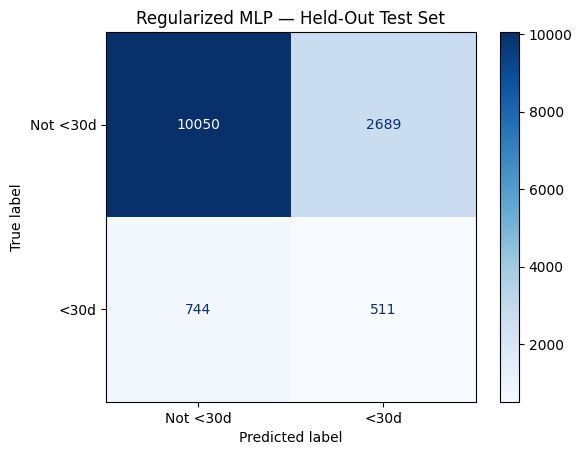

In [12]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Predict probabilities on the held-out test set
test_probs = regularized_model.predict(
    X_test_scaled, verbose=0
).ravel()

# Apply the threshold chosen on validation only
final_threshold = 0.56
test_preds = (test_probs >= final_threshold).astype(int)

# Compute final test metrics
test_metrics = {
    "PR-AUC": average_precision_score(y_test, test_probs),
    "ROC-AUC": roc_auc_score(y_test, test_probs),
    "Precision": precision_score(y_test, test_preds, zero_division=0),
    "Recall": recall_score(y_test, test_preds, zero_division=0),
    "F1": f1_score(y_test, test_preds, zero_division=0)
}

print("Final Test Results:")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

# Plot confusion matrix
cm = confusion_matrix(y_test, test_preds)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not <30d", "<30d"]
).plot(cmap="Blues", values_format="d")

plt.title("Regularized MLP — Held-Out Test Set")
plt.show()
